In [1]:
# CELL 1: Kitabxanaları import edir və parametrləri (VCF mənbəyi, süzgəc hədləri) təyin edir
import io, gzip, urllib.request, json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Real açıq VCF (SEQC2 HCC1395 somatik SNV truth set, GRCh38). Lazım olsa dəyişin:
VCF_SOURCE = ("https://ftp-trace.ncbi.nlm.nih.gov/ReferenceSamples/seqc/"
              "Somatic_Mutation_WG/release/latest/"
              "high-confidence_sSNV_in_HC_regions_v1.2.vcf.gz")
MAX_RECORDS = 60000          # None = bütün faylı oxu
MIN_DP, MIN_VAF, MIN_GQ = 20, 0.05, 20

In [17]:
# CELL 1b: SEQC2 WGS qovluğunun siyahısını oxuyur, MuTect2 VCF fayllarını tapıb VCF_SOURCE-u təyin edir
import re
DIR_URL = ("https://ftp-trace.ncbi.nlm.nih.gov/ReferenceSamples/seqc/"
           "Somatic_Mutation_WG/analysis/SNVs/vcfs/WGS/")
html = urllib.request.urlopen(DIR_URL, timeout=120).read().decode("utf-8", "ignore")
files = sorted(set(re.findall(r'href="([^"]+\.vcf\.gz)"', html)))
mutect = [f for f in files if "mutect" in f.lower()]
print("Cəmi VCF:", len(files), "| MuTect2 faylları:", len(mutect))
for f in mutect[:15]:
    print(f)

# Birinci MuTect2 faylını seçir (istəsəniz siyahıdan başqasını yazın)
VCF_SOURCE = DIR_URL + mutect[0]
MAX_RECORDS = 200000     # fayl xromosom sırası ilə gedir; böyük rəqəm daha çox xromosomu əhatə edir
print("Seçilən fayl:", VCF_SOURCE)

Cəmi VCF: 189 | MuTect2 faylları: 63
WGS_EA_1.bowtie.muTect2.vcf.gz
WGS_EA_1.bwa.muTect2.vcf.gz
WGS_EA_1.novo.muTect2.vcf.gz
WGS_FD_1.bowtie.muTect2.vcf.gz
WGS_FD_1.bwa.muTect2.vcf.gz
WGS_FD_1.novo.muTect2.vcf.gz
WGS_FD_2.bowtie.muTect2.vcf.gz
WGS_FD_2.bwa.muTect2.vcf.gz
WGS_FD_2.novo.muTect2.vcf.gz
WGS_FD_3.bowtie.muTect2.vcf.gz
WGS_FD_3.bwa.muTect2.vcf.gz
WGS_FD_3.novo.muTect2.vcf.gz
WGS_IL_1.bowtie.muTect2.vcf.gz
WGS_IL_1.bwa.muTect2.vcf.gz
WGS_IL_1.novo.muTect2.vcf.gz
Seçilən fayl: https://ftp-trace.ncbi.nlm.nih.gov/ReferenceSamples/seqc/Somatic_Mutation_WG/analysis/SNVs/vcfs/WGS/WGS_EA_1.bowtie.muTect2.vcf.gz


In [18]:
# CELL 2: VCF oxuma funksiyaları (lokal fayl, URL, .gz dəstəyi); meta, başlıq və cədvəl qaytarır
def open_text(source):
    if "\n" in source:
        return io.StringIO(source)
    if source.startswith("http"):
        stream = urllib.request.urlopen(source, timeout=180)
    else:
        stream = open(source, "rb")
    if source.endswith(".gz"):
        stream = gzip.GzipFile(fileobj=stream)
    return io.TextIOWrapper(stream, encoding="utf-8")

def read_vcf(source, max_records=None):
    meta, rows, header = [], [], None
    with open_text(source) as f:
        for line in f:
            line = line.rstrip("\n")
            if not line:
                continue
            if line.startswith("##"):
                meta.append(line)
            elif line.startswith("#CHROM"):
                header = line.lstrip("#").split("\t")
            else:
                rows.append(line.split("\t"))
                if max_records and len(rows) >= max_records:
                    break
    return meta, pd.DataFrame(rows, columns=header)

In [20]:
# CELL 3: Real VCF-i yükləyir, başlıq sətirlərini və ilk variantları göstərir
meta, df = read_vcf(VCF_SOURCE, MAX_RECORDS)
print(f"Başlıq (##) sətirləri: {len(meta)}, oxunan variant sayı: {len(df)}")
print("Sütunlar:", list(df.columns))
for m in meta:
    if m.startswith(("##INFO", "##FORMAT", "##FILTER", "##reference")):
        print(m)
df.head()

Başlıq (##) sətirləri: 2820, oxunan variant sayı: 200000
Sütunlar: ['CHROM', 'POS', 'ID', 'REF', 'ALT', 'QUAL', 'FILTER', 'INFO', 'FORMAT', 'TUMOR', 'NORMAL']
##FILTER=<ID=alt_allele_in_normal,Description="Evidence seen in the normal sample">
##FILTER=<ID=clustered_events,Description="Clustered events observed in the tumor">
##FILTER=<ID=clustered_read_position,Description="Evidence for somatic variant clusters near the ends of reads">
##FILTER=<ID=germline_risk,Description="Evidence indicates this site is germline, not somatic">
##FILTER=<ID=homologous_mapping_event,Description="More than three events were observed in the tumor">
##FILTER=<ID=multi_event_alt_allele_in_normal,Description="Multiple events observed in tumor and normal">
##FILTER=<ID=panel_of_normals,Description="Seen in at least 2 samples in the panel of normals">
##FILTER=<ID=str_contraction,Description="Site filtered due to contraction of short tandem repeat region">
##FILTER=<ID=strand_artifact,Description="Evidence f

,CHROM,POS,ID,REF,ALT,QUAL,FILTER,INFO,FORMAT,TUMOR,NORMAL
0,chr1,17492,.,C,CCA,.,PASS,ECNT=1;HCNT=1;MAX_ED=.;MIN_ED=.;NLOD=27.12;TLO...,GT:AD:AF:ALT_F1R2:ALT_F2R1:FOXOG:QSS:REF_F1R2:...,"0/1:30,3:0.091:1:2:.:1186,123:11:19","0/0:104,1:9.524e-03:1:0:.:4196,41:51:53"
1,chr1,62140,.,C,T,.,clustered_events;homologous_mapping_event,ECNT=4;HCNT=2;MAX_ED=63;MIN_ED=40;NLOD=8.43;TL...,GT:AD:AF:ALT_F1R2:ALT_F2R1:FOXOG:QSS:REF_F1R2:...,"0/1:1,2:0.667:1:1:0.500:41,82:1:0","0/0:28,0:0.00:0:0:.:1127,0:18:10"
2,chr1,62180,.,T,G,.,clustered_events;homologous_mapping_event;t_lo...,ECNT=4;HCNT=2;MAX_ED=63;MIN_ED=40;NLOD=10.53;T...,GT:AD:AF:ALT_F1R2:ALT_F2R1:FOXOG:PGT:PID:QSS:R...,"0/1:0,1:1.00:0:1:0.00:0|1:62180_T_G:0,41:0:0","0/0:36,0:0.00:0:0:.:0|1:62180_T_G:1422,0:20:16"
3,chr1,62190,.,A,C,.,clustered_events;homologous_mapping_event,ECNT=4;HCNT=2;MAX_ED=63;MIN_ED=40;NLOD=11.74;T...,GT:AD:AF:ALT_F1R2:ALT_F2R1:FOXOG:PGT:PID:QSS:R...,"0/1:0,2:1.00:1:1:0.500:0|1:62180_T_G:0,82:0:0","0/0:39,0:0.00:0:0:.:0|1:62180_T_G:1565,0:22:17"
4,chr1,62203,rs28402963,T,C,.,clustered_events;homologous_mapping_event,DB;ECNT=4;HCNT=2;MAX_ED=63;MIN_ED=40;NLOD=11.7...,GT:AD:AF:ALT_F1R2:ALT_F2R1:FOXOG:PGT:PID:QSS:R...,"0/1:0,2:1.00:1:1:0.500:0|1:62180_T_G:0,82:0:0","0/0:40,0:0.00:0:0:.:0|1:62180_T_G:1561,0:23:17"


In [21]:
# CELL 4: Sabit sütunları rəqəmə çevirir, SNV/INDEL tipini təyin edir, INFO-nu lüğətə açır
df["POS"] = df["POS"].astype(int)
df["QUAL"] = pd.to_numeric(df["QUAL"], errors="coerce")

def variant_type(ref, alt):
    alt1 = alt.split(",")[0]
    if len(ref) == 1 and len(alt1) == 1:
        return "SNV"
    return "INDEL" if len(ref) != len(alt1) else "MNV"

df["TYPE"] = [variant_type(r, a) for r, a in zip(df["REF"], df["ALT"])]

def parse_info(info):
    d = {}
    for item in info.split(";"):
        if "=" in item:
            k, v = item.split("=", 1)
            d[k] = v
        else:
            d[item] = True
    return d

df["INFO_D"] = df["INFO"].apply(parse_info)
print(df["TYPE"].value_counts())
print("INFO-da olan açarlar:", sorted({k for d in df["INFO_D"].head(2000) for k in d}))

TYPE
SNV      175316
INDEL     24684
Name: count, dtype: int64
INFO-da olan açarlar: ['DB', 'ECNT', 'HCNT', 'MAX_ED', 'MIN_ED', 'NLOD', 'RPA', 'RU', 'STR', 'TLOD']


In [22]:
# CELL 5: NORMAL/TUMOR sütunlarını tapır; DP, AF(VAF), GQ-ni FORMAT-dan (yoxdursa INFO-dan) çıxarır
fixed = ["CHROM","POS","ID","REF","ALT","QUAL","FILTER","INFO","FORMAT","TYPE","INFO_D"]
sample_cols = [c for c in df.columns if c not in fixed]
NORMAL = TUMOR = None
if len(sample_cols) >= 2:
    normal_guess = [c for c in sample_cols if "normal" in c.lower() or "BL" in c]
    NORMAL = normal_guess[0] if normal_guess else sample_cols[0]
    TUMOR = [c for c in sample_cols if c != NORMAL][0]
elif len(sample_cols) == 1:
    TUMOR = sample_cols[0]
print("NORMAL:", NORMAL, "| TUMOR:", TUMOR)

def metric(row, sample, key):
    val = None
    if sample is not None and "FORMAT" in row:
        d = dict(zip(row["FORMAT"].split(":"), row[sample].split(":")))
        val = d.get(key)
    if val is None:
        val = row["INFO_D"].get(key)
    try:
        return float(str(val).split(",")[0])
    except (TypeError, ValueError):
        return np.nan

for s, tag in ((NORMAL, "NORMAL"), (TUMOR, "TUMOR")):
    for key in ("DP", "GQ", "AF"):
        df[f"{key}_{tag}"] = df.apply(lambda r: metric(r, s, key), axis=1)

print(df[[c for c in df.columns if c.split("_")[0] in ("DP","GQ","AF")]].notna().sum())

NORMAL: NORMAL | TUMOR: TUMOR
DP_NORMAL         0
GQ_NORMAL         0
AF_NORMAL    199327
DP_TUMOR          0
GQ_TUMOR          0
AF_TUMOR     200000
dtype: int64


C:\Users\Acer\AppData\Local\Temp\ipykernel_6588\2279955073.py:21: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout(); plt.show()


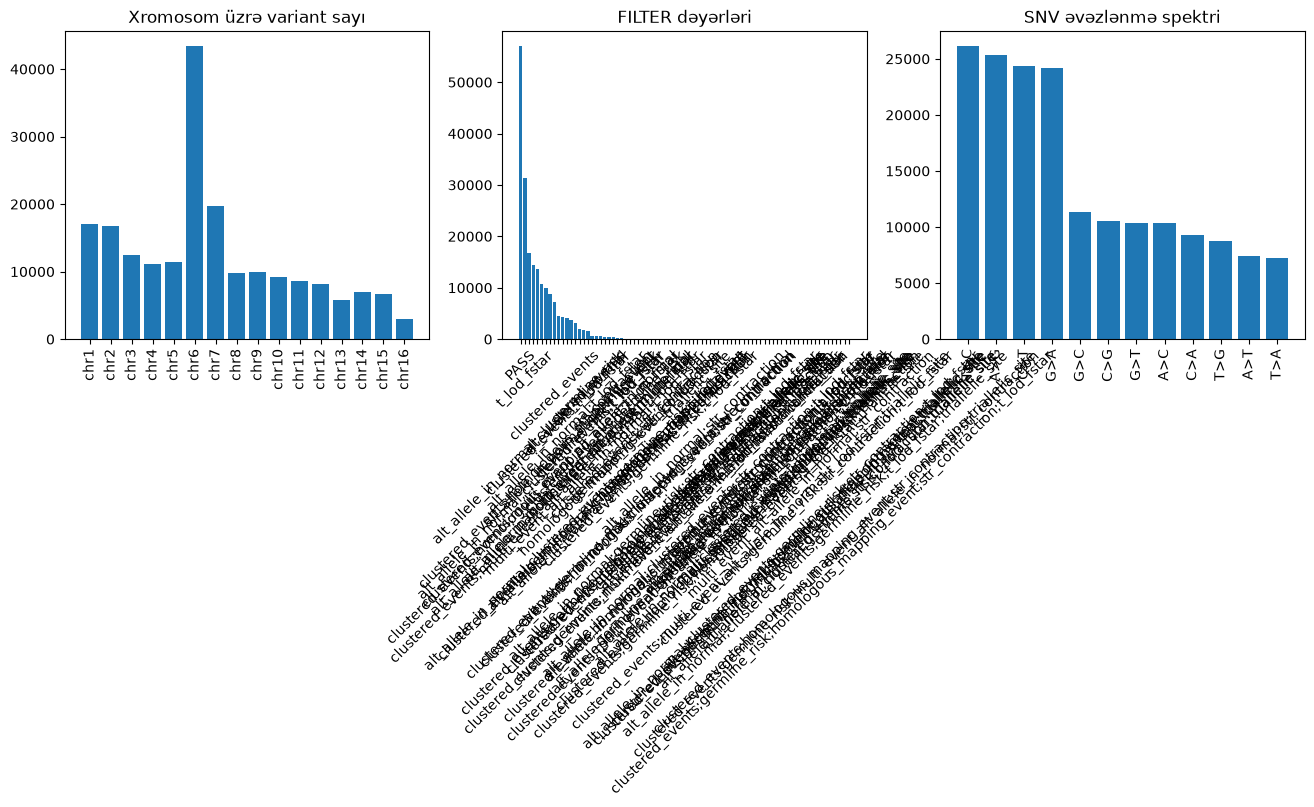

In [23]:
# CELL 6: Ümumi mənzərə: xromosom üzrə paylanma, FILTER dəyərləri və SNV əvəzlənmə spektri (C>T artefakt nəzarəti)
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

order = [f"chr{i}" for i in list(range(1, 23)) + ["X", "Y"]]
chrom_counts = df["CHROM"].value_counts().reindex(order).dropna()
axes[0].bar(chrom_counts.index, chrom_counts.values)
axes[0].set_title("Xromosom üzrə variant sayı")
axes[0].tick_params(axis="x", rotation=90)

fc = df["FILTER"].value_counts()
axes[1].bar(fc.index, fc.values)
axes[1].set_title("FILTER dəyərləri")
axes[1].tick_params(axis="x", rotation=45)

snv = df[df["TYPE"] == "SNV"]
spec = (snv["REF"] + ">" + snv["ALT"]).value_counts()
axes[2].bar(spec.index, spec.values)
axes[2].set_title("SNV əvəzlənmə spektri")
axes[2].tick_params(axis="x", rotation=90)

plt.tight_layout(); plt.show()

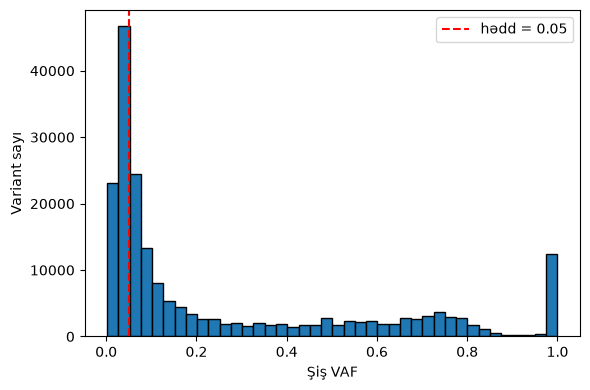

In [24]:
# CELL 7: Süzgəc hədlərini seçməzdən əvvəl DP və VAF paylanmasına baxır (dəyər yoxdursa keçir)
cols_to_plot = [("DP_TUMOR", MIN_DP, "Şiş DP"), ("AF_TUMOR", MIN_VAF, "Şiş VAF")]
available = [c for c in cols_to_plot if df[c[0]].notna().any()]
if not available:
    print("Bu faylda DP/VAF yoxdur (sites-only VCF). Mutect2 çağırış faylı seçin (Cell 1).")
else:
    fig, axes = plt.subplots(1, len(available), figsize=(6*len(available), 4), squeeze=False)
    for ax, (col, thr, label) in zip(axes[0], available):
        ax.hist(df[col].dropna(), bins=40, edgecolor="black")
        ax.axvline(thr, linestyle="--", color="red", label=f"hədd = {thr}")
        ax.set_xlabel(label); ax.set_ylabel("Variant sayı"); ax.legend()
    plt.tight_layout(); plt.show()

In [25]:
# CELL 7b: FILTER dəyərlərini və Cell 8 nəticələrini yoxlayır
print(df["FILTER"].value_counts().head(10))
print("hq ölçüsü:", len(hq))

FILTER
PASS                                                             57081
t_lod_fstar                                                      31420
alt_allele_in_normal;clustered_events                            16683
clustered_events;homologous_mapping_event;t_lod_fstar            14391
clustered_events;homologous_mapping_event                        13720
alt_allele_in_normal;clustered_events;t_lod_fstar                10663
clustered_events;multi_event_alt_allele_in_normal;t_lod_fstar    10042
clustered_events;multi_event_alt_allele_in_normal                 8841
clustered_events                                                  7158
clustered_events;t_lod_fstar                                      4558
Name: count, dtype: int64
hq ölçüsü: 400


In [27]:
# CELL 8 (düzəldilmiş): Mənşəyi təyin edir, süzgəcləri tətbiq edir; PASS və güvən səviyyəsi (HighConf) addımları əlavə olunub
def origin(normal_vaf):
    if np.isnan(normal_vaf):
        return "unknown"
    if normal_vaf >= 0.30:
        return "germline"
    if normal_vaf <= 0.02:
        return "somatic"
    return "uncertain"

df["ORIGIN"] = df["AF_NORMAL"].apply(origin)

def present(col):
    return df[col].notna().any()

is_pass = df["FILTER"].str.startswith("PASS")
is_high = df["FILTER"].str.contains("HighConf")

steps = [("Bütün variantlar", pd.Series(True, index=df.index)),
         ("FILTER PASS (HighConf+MedConf)", is_pass)]
if is_high.any():
    steps.append(("Yalnız HighConf", is_high))

if present("DP_TUMOR"):  steps.append((f"Şiş DP >= {MIN_DP}",   df["DP_TUMOR"] >= MIN_DP))
if present("AF_TUMOR"):  steps.append((f"Şiş VAF >= {MIN_VAF}", df["AF_TUMOR"] >= MIN_VAF))
if present("GQ_TUMOR"):  steps.append((f"Şiş GQ >= {MIN_GQ}",   df["GQ_TUMOR"] >= MIN_GQ))
if present("AF_NORMAL"): steps.append(("Somatik mənşəli", df["ORIGIN"] == "somatic"))
else: print("Normal VAF yoxdur: somatik/germline ayrımı atlandı.")

keep = pd.Series(True, index=df.index)
counts = []
for name, cond in steps:
    keep &= cond
    counts.append((name, int(keep.sum())))
for name, n in counts:
    print(f"{name:<32} {n}")
hq = df[keep].copy()
print("hq ölçüsü:", len(hq))

Bütün variantlar                 200000
FILTER PASS (HighConf+MedConf)   57081
Şiş VAF >= 0.05                  55047
Somatik mənşəli                  53956
hq ölçüsü: 53956


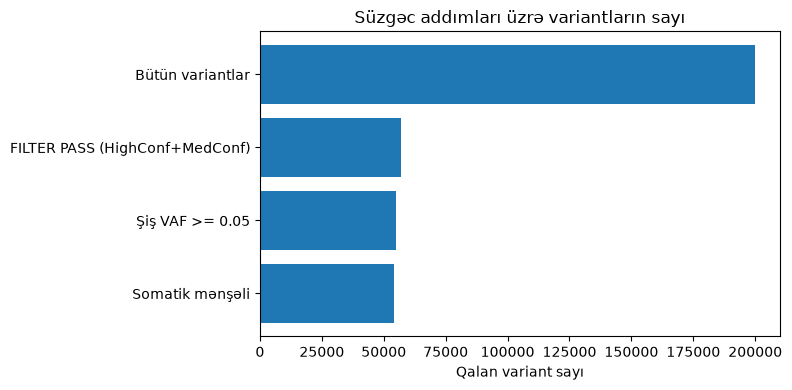

In [28]:
# CELL 9: Süzgəc addımları üzrə qalan variant sayını üfüqi sütun qrafiki ilə göstərir
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh([c[0] for c in counts][::-1], [c[1] for c in counts][::-1])
ax.set_xlabel("Qalan variant sayı")
ax.set_title("Süzgəc addımları üzrə variantların sayı")
plt.tight_layout(); plt.show()

In [ ]:
# CELL 10 (düzəldilmiş): Annotasiyanı oxuyur; yoxdursa Ensembl VEP ilə nümunəni annotasiya edir (kiçik paketlər, təkrar cəhd, xətalı variantı təcrid etmə)
assert len(hq) > 0, "hq boşdur: Cell 8 çıxışına baxın."

def parse_ann(info_d):
    if "ANN" in info_d:
        f = info_d["ANN"].split(",")[0].split("|")
        return (f[3], f[1], f[2])
    return (None, None, None)

hq["GENE"], hq["EFFECT"], hq["IMPACT"] = zip(*hq["INFO_D"].apply(parse_ann))

if hq["GENE"].isna().all():
    N_ANN = 400
    std_chroms = {f"chr{c}" for c in list(range(1, 23)) + ["X", "Y"]}
    cand = hq[hq["CHROM"].isin(std_chroms)
              & ~hq["ALT"].str.contains(r"[*<>]", regex=True)].copy()
    sample = cand.sample(min(N_ANN, len(cand)), random_state=42).copy()

    def to_vep(r):
        return f'{r["CHROM"].replace("chr","")} {r["POS"]} . {r["REF"]} {r["ALT"].split(",")[0]} . . .'
    sample["VEP_IN"] = sample.apply(to_vep, axis=1)

    URL = "https://rest.ensembl.org/vep/human/region?pick=1"
    HEADERS = {"Content-Type": "application/json", "Accept": "application/json",
               "User-Agent": "Mozilla/5.0 (VCF-lesson)"}
    results, failed = {}, []

    def vep_call(batch, tries=3):
        body = json.dumps({"variants": batch}).encode()
        for t in range(tries):
            try:
                req = urllib.request.Request(URL, data=body, headers=HEADERS)
                with urllib.request.urlopen(req, timeout=120) as resp:
                    return json.loads(resp.read())
            except Exception as e:
                time.sleep(2 * (t + 1))
        return None

    def run(batch):
        data = vep_call(batch)
        if data is None:
            if len(batch) == 1:
                failed.append(batch[0]); return
            mid = len(batch) // 2          # paketi böl, xətalı variantı təcrid et
            run(batch[:mid]); run(batch[mid:])
            return
        for item in data:
            tc = (item.get("transcript_consequences") or [{}])[0]
            results[item["input"]] = (tc.get("gene_symbol"),
                                      item.get("most_severe_consequence"),
                                      tc.get("impact"))

    lst = sample["VEP_IN"].tolist()
    for i in range(0, len(lst), 50):
        run(lst[i:i+50])
        time.sleep(0.5)
    print(f"Annotasiya olunan: {len(results)}, uğursuz: {len(failed)}")

    vals = [results.get(v, (None, None, None)) for v in sample["VEP_IN"]]
    sample["GENE"], sample["EFFECT"], sample["IMPACT"] = zip(*vals)
    hq = sample

print(hq["IMPACT"].value_counts(dropna=False))
hq[["CHROM", "POS", "REF", "ALT", "TYPE", "GENE", "EFFECT", "IMPACT"]].head(15)

In [ ]:
# CELL 11: HIGH və MODERATE təsirli (potensial zərərli) variantları seçir, SNV/INDEL sayır və CSV-yə yazır
deleterious = hq[hq["IMPACT"].isin(["HIGH", "MODERATE"])]
print("SNV və indel sayı:")
print(deleterious["TYPE"].value_counts())
print("\nƏn çox mutasiyalı genlər:")
print(deleterious["GENE"].value_counts().head(10))

show_cols = ["GENE", "CHROM", "POS", "REF", "ALT", "TYPE", "EFFECT", "IMPACT"]
if present("AF_TUMOR"):
    show_cols.append("AF_TUMOR")
deleterious.to_csv("somatic_high_quality.csv", index=False,
                   columns=show_cols)
deleterious[show_cols].head(20)

In [ ]:
# CELL 12 (düzəldilmiş): VAF həddinin təsirini yoxlayır; PASS şərti startswith ilə, metrik yoxdursa xəbərdarlıq verir
if present("AF_TUMOR"):
    for vaf in (0.02, 0.05, 0.10, 0.20):
        cond = df["FILTER"].str.startswith("PASS") & (df["AF_TUMOR"] >= vaf)
        if present("DP_TUMOR"):
            cond &= df["DP_TUMOR"] >= MIN_DP
        if present("AF_NORMAL"):
            cond &= df["ORIGIN"] == "somatic"
        print(f"VAF >= {vaf:<4} -> {int(cond.sum())} variant")
else:
    print("Bu faylda VAF yoxdur (truth set sites-only). Bu təcrübə üçün Mutect2 VCF faylı lazımdır.")